# 1. Frame the problem and explore the data

This notebook covers the first two sections of the INSY 674 rubric:
1. Frame the problem and look at the big picture
2. Explore the data

## 1.1 Frame the problem and look at the big picture

### Objective
Build an exploratory foundation for an audit model that predicts how much the final incurred claim cost will differ from the adjuster's initial reserve at first notice of loss (FNOL). The prediction is intended to flag claims for human review, not replace actuarial judgment.

### How the solution will be used
Claims and reserving teams could use a predicted reserve shortfall to prioritize case-manager review and compare the model's estimate with the initial reserve. Any intervention or financial benefit must be evaluated prospectively; this dataset alone does not establish that an intervention prevents losses.

### Current solution and benchmark
The observed baseline is the initial incurred-cost estimate recorded in the dataset. Compare it with `UltimateIncurredClaimCost` to quantify historical reserve error. This is a retrospective benchmark, not proof of an adjuster's causal error: the dataset is synthetic/competition data and does not provide the full information available to the adjuster at FNOL.

### Problem framing and performance measure
This is supervised regression. The primary audit target is the dollar reserve shortfall, `UltimateIncurredClaimCost - InitialIncurredCalimsCost` (positive means under-reserving; negative means over-reserving). A secondary scale-normalized target is the log development ratio, `log(UltimateIncurredClaimCost / InitialIncurredCalimsCost)`, defined only when both costs are positive. Report dollar MAE/RMSE and the human-reserve baseline on held-out data; also inspect under-reserving separately because its business cost may be asymmetric. Keep `ClaimNumber` out of predictors, and do not use information unavailable at FNOL.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

RAW_DATA_DIR = Path("../data/raw")
FIGURES_DIR = Path("../reports/figures")
INITIAL_COST_COL = "InitialIncurredCalimsCost"
ULTIMATE_COST_COL = "UltimateIncurredClaimCost"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

In [2]:
list(RAW_DATA_DIR.iterdir())

[PosixPath('../data/raw/.gitkeep'), PosixPath('../data/raw/train.csv')]

In [3]:
df = pd.read_csv(RAW_DATA_DIR / "train.csv")

print("Dataset shape:", df.shape)
display(df.head())
display(df.sample(min(5, len(df)), random_state=RANDOM_STATE))

Dataset shape: (36176, 15)


,ClaimNumber,DateTimeOfAccident,DateReported,Age,Gender,MaritalStatus,DependentChildren,DependentsOther,WeeklyWages,PartTimeFullTime,HoursWorkedPerWeek,DaysWorkedPerWeek,ClaimDescription,InitialIncurredCalimsCost,UltimateIncurredClaimCost
0,WC8205482,2002-04-09T07:00:00Z,2002-07-05T00:00:00Z,48,M,M,0,0,500.00,F,38.00,5,LIFTING TYRE INJURY TO RIGHT ARM AND WRIST INJURY,1500,"4,748.20"
1,WC6922469,1999-01-07T11:00:00Z,1999-01-20T00:00:00Z,43,F,M,0,0,509.34,F,37.50,5,STEPPED AROUND CRATES AND TRUCK TRAY FRACTURE ...,5500,"6,326.29"
2,WC5442654,1996-03-25T00:00:00Z,1996-04-14T00:00:00Z,30,M,U,0,0,709.10,F,38.00,5,CUT ON SHARP EDGE CUT LEFT THUMB,1700,"2,293.95"
3,WC9796897,2005-06-22T13:00:00Z,2005-07-22T00:00:00Z,41,M,S,0,0,555.46,F,38.00,5,DIGGING LOWER BACK LOWER BACK STRAIN,15000,"17,786.49"
4,WC2603726,1990-08-29T08:00:00Z,1990-09-27T00:00:00Z,36,M,M,0,0,377.10,F,38.00,5,REACHING ABOVE SHOULDER LEVEL ACUTE MUSCLE STR...,2800,"4,014.00"


,ClaimNumber,DateTimeOfAccident,DateReported,Age,Gender,MaritalStatus,DependentChildren,DependentsOther,WeeklyWages,PartTimeFullTime,HoursWorkedPerWeek,DaysWorkedPerWeek,ClaimDescription,InitialIncurredCalimsCost,UltimateIncurredClaimCost
35985,WC3993539,1993-11-30T12:00:00Z,1993-12-29T00:00:00Z,20,M,S,0,0,520.00,F,37.50,5,KNIFE SLIPPED AND CUT HEAD AND KNEE,7500,"6,638.23"
11660,WC7541275,2000-07-03T17:00:00Z,2000-08-07T00:00:00Z,28,M,S,0,0,200.00,F,38.00,5,STRAIGHTENING METAL SLIPPED STRUCK WRIST FRACT...,1500,"1,474.91"
31002,WC9770897,2005-10-31T11:00:00Z,2005-11-16T00:00:00Z,44,M,S,0,0,707.80,F,38.00,5,REPETITIVE WORK STRAIN RIGHT SHOULDER STRAIN,11000,"19,296.95"
12414,WC6642266,1998-11-26T11:00:00Z,1999-01-16T00:00:00Z,50,M,M,0,0,200.00,F,40.00,5,LIFTING AND SCREENS STRAIN LOWER BACK STRAIN,10000,"5,218.07"
33545,WC7922579,2001-11-29T08:00:00Z,2001-12-17T00:00:00Z,35,M,M,2,0,200.00,F,40.00,5,CUTTING BASIL LACERATION RIGHT LITTLE FINGER,500,316.59


In [4]:
eda_df = df.copy()

# Optional: use a reproducible sample for exploratory plots.
eda_sample = eda_df.sample(
    n=min(10_000, len(eda_df)),
    random_state=RANDOM_STATE
)

print("Full data:", eda_df.shape)
print("Exploration sample:", eda_sample.shape)

Full data: (36176, 15)
Exploration sample: (10000, 15)


## 1.2 Load a copy of the data for exploration

Create an exploration copy (and sample down if the dataset is too large) without modifying the raw source file.

In [5]:
explore_df = eda_df.copy()
print(f"Exploration copy: {explore_df.shape}")

Exploration copy: (36176, 15)


## 1.3 Study each attribute and its characteristics

The profile table below labels every attribute by the rubric's requested **name**, **type/structure**, **percentage missing**, **noise or data-quality caveats**, **distribution/range**, and **usefulness for the task**. The role column identifies the supervised outcome and the record identifier.

Numeric summaries report range and skew; categorical, date, and text fields include level counts or value summaries. The data-quality checks later in the notebook inspect noisy or implausible values without automatically deleting them.

Source column names are preserved. In particular, `InitialIncurredCalimsCost` is misspelled in the CSV.

In [6]:
print("Shape:", eda_df.shape)
print("Duplicate rows:", eda_df.duplicated().sum())

eda_df.info()

display(eda_df.describe(include="all").T)

Shape: (36176, 15)
Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36176 entries, 0 to 36175
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ClaimNumber                36176 non-null  object 
 1   DateTimeOfAccident         36176 non-null  object 
 2   DateReported               36176 non-null  object 
 3   Age                        36176 non-null  int64  
 4   Gender                     36176 non-null  object 
 5   MaritalStatus              36154 non-null  object 
 6   DependentChildren          36176 non-null  int64  
 7   DependentsOther            36176 non-null  int64  
 8   WeeklyWages                36120 non-null  float64
 9   PartTimeFullTime           36176 non-null  object 
 10  HoursWorkedPerWeek         36127 non-null  float64
 11  DaysWorkedPerWeek          36176 non-null  int64  
 12  ClaimDescription           36176 non-null  object 
 13  InitialIn

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ClaimNumber,36176,29456,WC7301773,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DateTimeOfAccident,36176,27549,1994-02-23T11:00:00Z,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DateReported,36176,6583,2001-03-29T00:00:00Z,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,"36,176.00",NaN,NaN,NaN,33.80,12.11,13.00,23.00,32.00,43.00,79.00
Gender,36176,3,M,27919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaritalStatus,36154,3,S,17450,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DependentChildren,"36,176.00",NaN,NaN,NaN,0.12,0.53,0.00,0.00,0.00,0.00,9.00
DependentsOther,"36,176.00",NaN,NaN,NaN,0.01,0.11,0.00,0.00,0.00,0.00,3.00
WeeklyWages,"36,120.00",NaN,NaN,NaN,416.47,243.88,1.00,200.00,393.37,500.00,"7,497.00"
PartTimeFullTime,36176,2,F,32917,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
def profile_attributes(df: pd.DataFrame) -> pd.DataFrame:
    """Generate a structured summary table of all attributes for the rubric."""
    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(),
    })
    num_cols = df.select_dtypes(include=[np.number]).columns
    summary.loc[num_cols, "mean"] = df[num_cols].mean().round(3)
    summary.loc[num_cols, "std"] = df[num_cols].std().round(3)
    summary.loc[num_cols, "min"] = df[num_cols].min()
    summary.loc[num_cols, "median"] = df[num_cols].median()
    summary.loc[num_cols, "max"] = df[num_cols].max()
    summary.loc[num_cols, "skewness"] = df[num_cols].skew().round(2)
    return summary

# profile_table = profile_attributes(explore_df)
# display(profile_table)

In [8]:
column_notes = {
    "ClaimNumber": ("identifier", "Structured ID; repeated IDs may link multiple records", "Exclude from predictors; use only for record linkage"),
    "DateTimeOfAccident": ("timestamp", "Structured date/time; verify parsing and unusual dates", "Potentially useful for calendar trends; derive FNOL-available features"),
    "DateReported": ("timestamp", "Structured date; can precede accident due to recording/rounding noise", "Useful for reporting delay if available at FNOL"),
    "Age": ("bounded integer", "Check implausible ages and heaping at whole years", "May proxy severity or recovery patterns; audit fairness"),
    "Gender": ("categorical", "Check inconsistent or rare labels", "Potential signal, but sensitive attribute; assess fairness before use"),
    "MaritalStatus": ("categorical", "Missing and possibly abbreviated categories", "Likely indirect/weak signal; consider fairness and privacy"),
    "DependentChildren": ("nonnegative count", "Discrete and likely zero-inflated; check extremes", "Possible wage-loss context; not a direct injury-severity measure"),
    "DependentsOther": ("nonnegative count", "Discrete and likely zero-inflated; check extremes", "Possible household context; not a direct injury-severity measure"),
    "WeeklyWages": ("nonnegative continuous currency", "Right tail, rounding, and missing values", "Useful for wage-loss exposure; adjust for historical inflation"),
    "PartTimeFullTime": ("binary category", "Validate labels and consistency with hours", "Useful employment context"),
    "HoursWorkedPerWeek": ("bounded continuous hours", "Missing, rounded, and potentially implausible values", "Useful employment context; check against 0-168 hours"),
    "DaysWorkedPerWeek": ("bounded integer count", "Discrete; verify values are within 0-7", "Useful employment context"),
    "ClaimDescription": ("free text", "Abbreviations, spelling variation, and inconsistent phrasing", "Potentially informative injury/mechanism signal; tokenize and vectorize"),
    "InitialIncurredCalimsCost": ("nonnegative currency", "Rounded reserve with a heavy right tail and extreme claims", "Observed human-reserve benchmark and available-at-FNOL predictor; source column has a spelling typo"),
    "UltimateIncurredClaimCost": ("nonnegative currency", "Heavy right tail and extreme claims; outcome is fully observed here", "Outcome only; never use as a predictor"),
}

feature_audit = pd.DataFrame({
    "name": eda_df.columns,
    "dtype": eda_df.dtypes.astype(str).values,
    "missing_count": eda_df.isna().sum().values,
    "missing_pct": (eda_df.isna().mean().values * 100).round(2),
    "unique_values": eda_df.nunique(dropna=True).values,
})
feature_audit["type / structure"] = feature_audit["name"].map(
    lambda col: column_notes.get(col, ("review type", "", ""))[0]
)
feature_audit["noise / caveat"] = feature_audit["name"].map(
    lambda col: column_notes.get(col, ("", "Review unusual values", ""))[1]
)
feature_audit["task usefulness"] = feature_audit["name"].map(
    lambda col: column_notes.get(col, ("", "", "Review usefulness"))[2]
)
numeric_cols_full = eda_df.select_dtypes(include=np.number).columns
numeric_skew = eda_df[numeric_cols_full].skew()
feature_audit["distribution / range"] = feature_audit["name"].map(
    lambda col: (
        f"min={eda_df[col].min():,.2f}, median={eda_df[col].median():,.2f}, "
        f"max={eda_df[col].max():,.2f}; "
        f"{'right-skewed' if numeric_skew[col] > 1 else 'left-skewed' if numeric_skew[col] < -1 else 'roughly symmetric'}"
        if col in numeric_cols_full
        else f"{eda_df[col].nunique(dropna=True)} distinct values; categorical/text/date-like"
    )
)
feature_audit["role"] = np.where(
    feature_audit["name"].eq("UltimateIncurredClaimCost"),
    "supervised outcome",
    np.where(feature_audit["name"].eq("ClaimNumber"), "identifier", "candidate input; check FNOL availability"),
)
display(feature_audit.sort_values("missing_pct", ascending=False))

,name,dtype,missing_count,missing_pct,unique_values,type / structure,noise / caveat,task usefulness,distribution / range,role
8,WeeklyWages,float64,56,0.15,10468,nonnegative continuous currency,"Right tail, rounding, and missing values",Useful for wage-loss exposure; adjust for hist...,"min=1.00, median=393.37, max=7,497.00; right-s...",candidate input; check FNOL availability
10,HoursWorkedPerWeek,float64,49,0.14,355,bounded continuous hours,"Missing, rounded, and potentially implausible ...",Useful employment context; check against 0-168...,"min=0.00, median=38.00, max=640.00; right-skewed",candidate input; check FNOL availability
5,MaritalStatus,object,22,0.06,3,categorical,Missing and possibly abbreviated categories,Likely indirect/weak signal; consider fairness...,3 distinct values; categorical/text/date-like,candidate input; check FNOL availability
0,ClaimNumber,object,0,0.00,29456,identifier,Structured ID; repeated IDs may link multiple ...,Exclude from predictors; use only for record l...,29456 distinct values; categorical/text/date-like,identifier
1,DateTimeOfAccident,object,0,0.00,27549,timestamp,Structured date/time; verify parsing and unusu...,Potentially useful for calendar trends; derive...,27549 distinct values; categorical/text/date-like,candidate input; check FNOL availability
2,DateReported,object,0,0.00,6583,timestamp,Structured date; can precede accident due to r...,Useful for reporting delay if available at FNOL,6583 distinct values; categorical/text/date-like,candidate input; check FNOL availability
3,Age,int64,0,0.00,65,bounded integer,Check implausible ages and heaping at whole years,May proxy severity or recovery patterns; audit...,"min=13.00, median=32.00, max=79.00; roughly sy...",candidate input; check FNOL availability
4,Gender,object,0,0.00,3,categorical,Check inconsistent or rare labels,"Potential signal, but sensitive attribute; ass...",3 distinct values; categorical/text/date-like,candidate input; check FNOL availability
6,DependentChildren,int64,0,0.00,9,nonnegative count,Discrete and likely zero-inflated; check extremes,Possible wage-loss context; not a direct injur...,"min=0.00, median=0.00, max=9.00; right-skewed",candidate input; check FNOL availability
7,DependentsOther,int64,0,0.00,4,nonnegative count,Discrete and likely zero-inflated; check extremes,Possible household context; not a direct injur...,"min=0.00, median=0.00, max=3.00; right-skewed",candidate input; check FNOL availability


## 1.4 Identify the target attribute(s) and visualize the data

For the proposed reserve-audit task, the primary supervised-learning target is `ReserveShortfall = UltimateIncurredClaimCost - InitialIncurredCalimsCost`; positive values mean under-reserving and negative values mean over-reserving. `LogDevelopmentRatio = log(UltimateIncurredClaimCost / InitialIncurredCalimsCost)` is a scale-normalized alternative, defined here because both costs are positive in all rows. `UltimateIncurredClaimCost` is the observed outcome used to derive these audit targets (and could be modeled directly for a different task); it and all target-derived fields must be excluded from predictors. The cells below visualize missingness, attribute distributions, target development, and reporting delay. Each chart has a title and labeled axes; interpretation is summarized below.

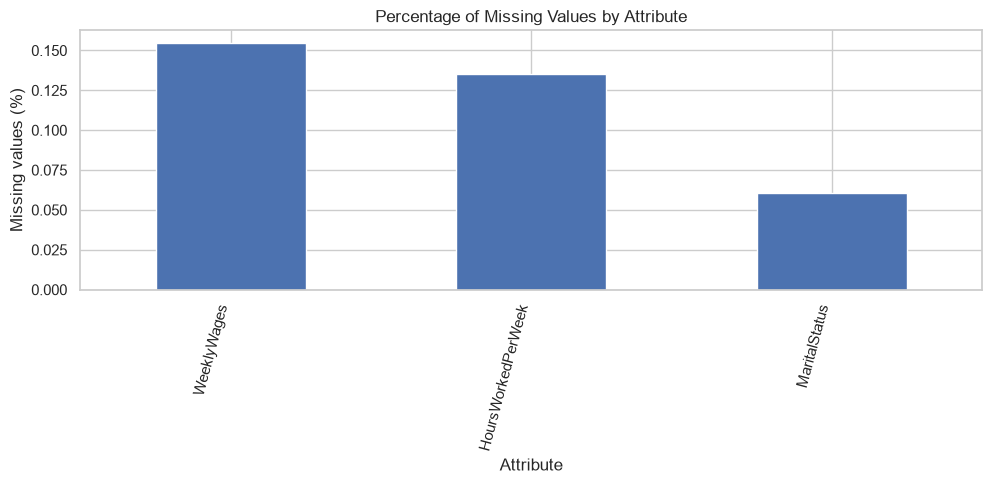

In [9]:
# Plot target distribution (raw vs. log-transformed if skewed)
missing_pct = (
    eda_df.isna().mean().mul(100)
    .sort_values(ascending=False)
)

missing_pct = missing_pct[missing_pct > 0]

if len(missing_pct) > 0:
    plt.figure(figsize=(10, 5))
    missing_pct.plot(kind="bar")
    plt.ylabel("Missing values (%)")
    plt.xlabel("Attribute")
    plt.title("Percentage of Missing Values by Attribute")
    plt.xticks(rotation=75, ha="right")
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "missing_values.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
else:
    print("No missing values found.")

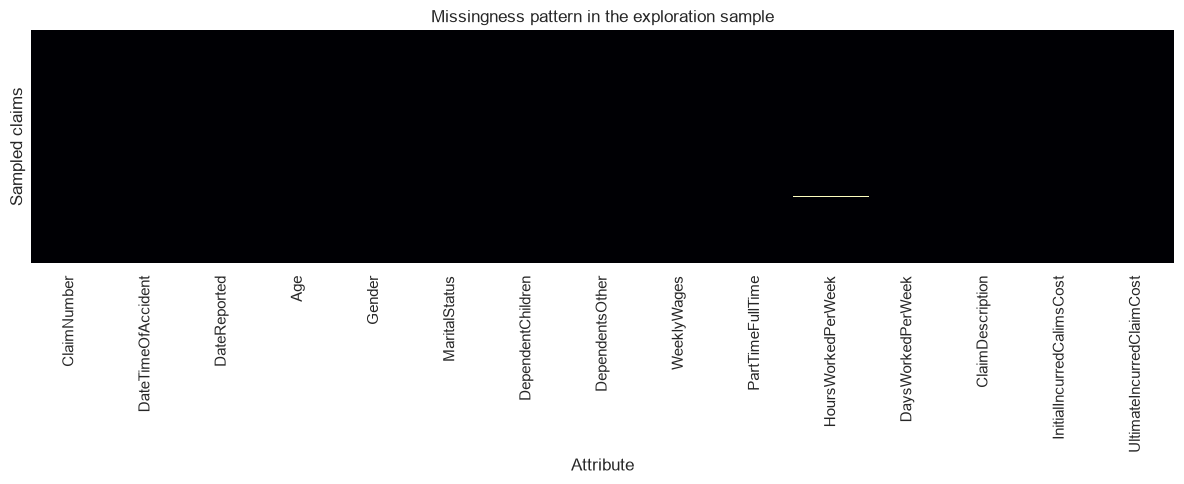

In [10]:
plt.figure(figsize=(12, 5))
sns.heatmap(eda_sample.isna(), cbar=False, yticklabels=False, cmap="magma")
plt.title("Missingness pattern in the exploration sample")
plt.xlabel("Attribute")
plt.ylabel("Sampled claims")
plt.tight_layout()
plt.show()

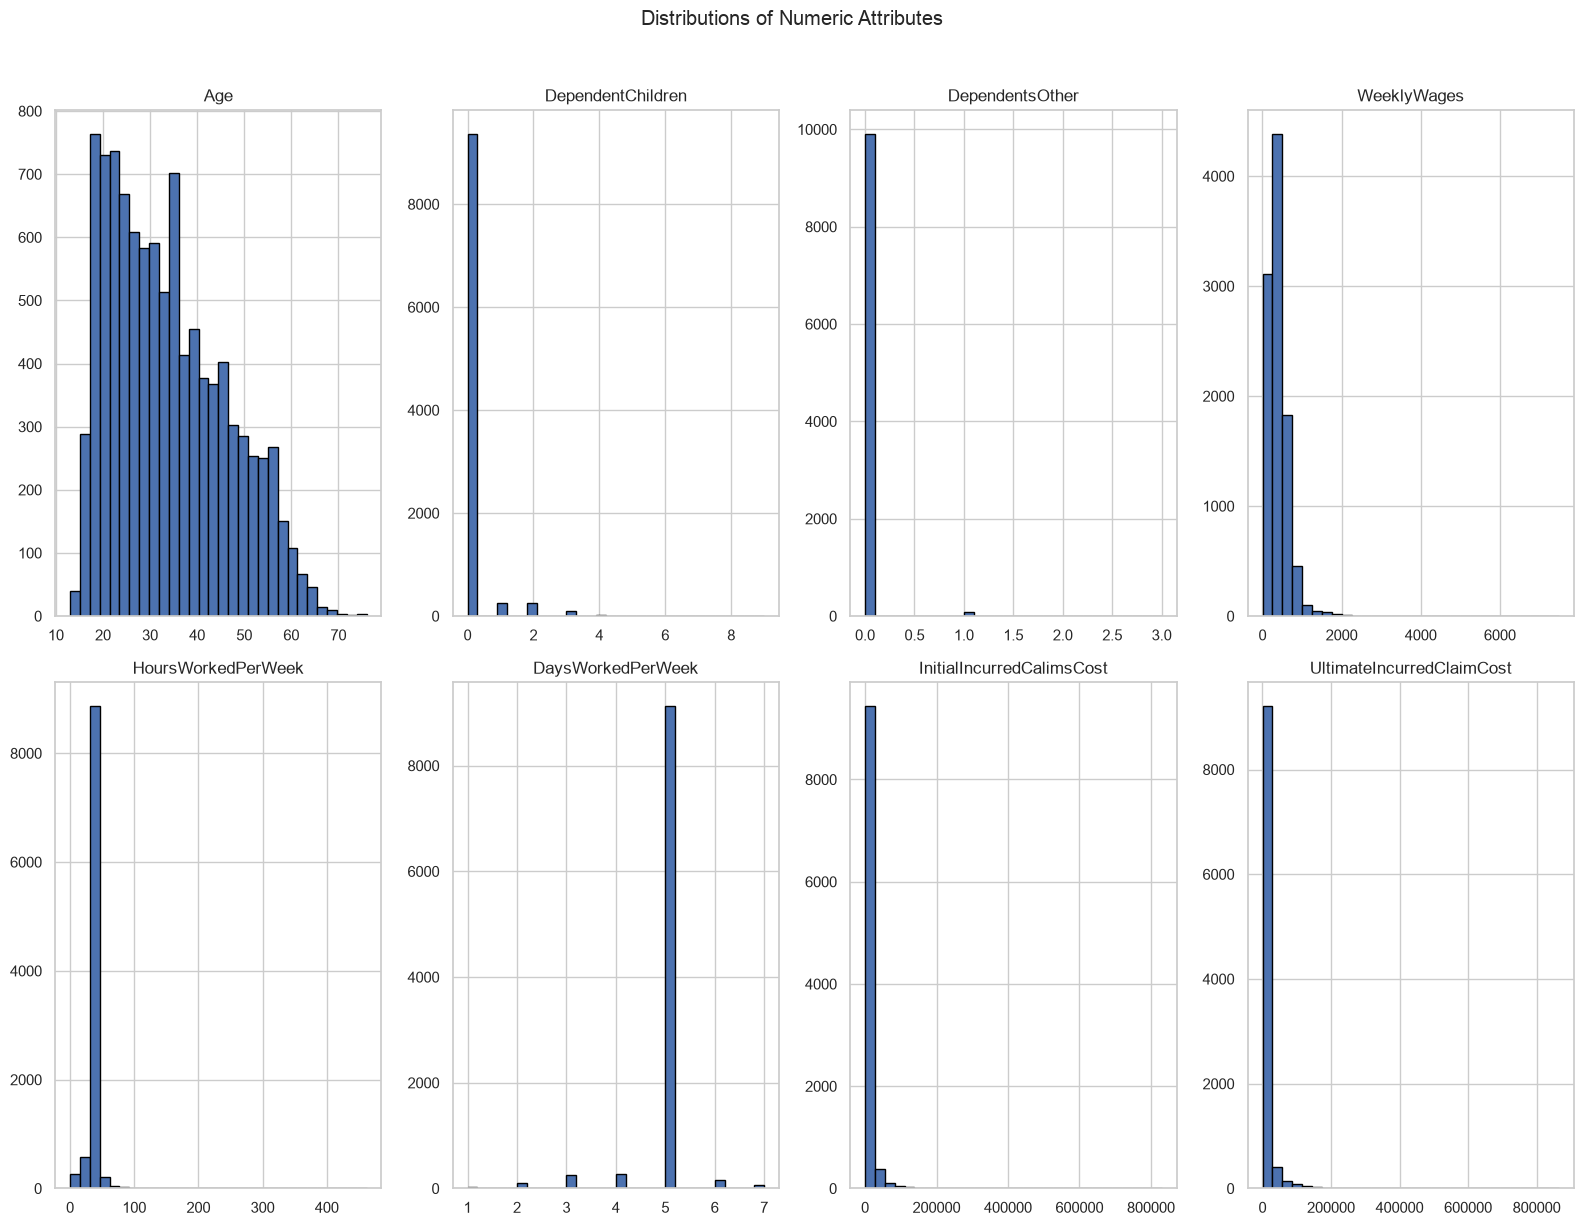

In [11]:
numeric_cols = eda_sample.select_dtypes(
    include=np.number
).columns.tolist()

eda_sample[numeric_cols].hist(
    bins=30,
    figsize=(16, 12),
    layout=(-1, 4),
    edgecolor="black"
)

plt.suptitle("Distributions of Numeric Attributes", y=1.02)
plt.tight_layout()
plt.show()

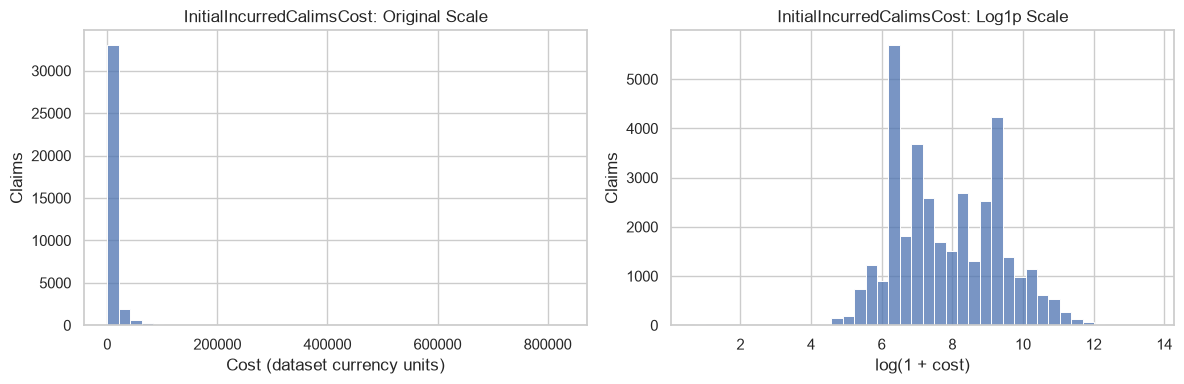

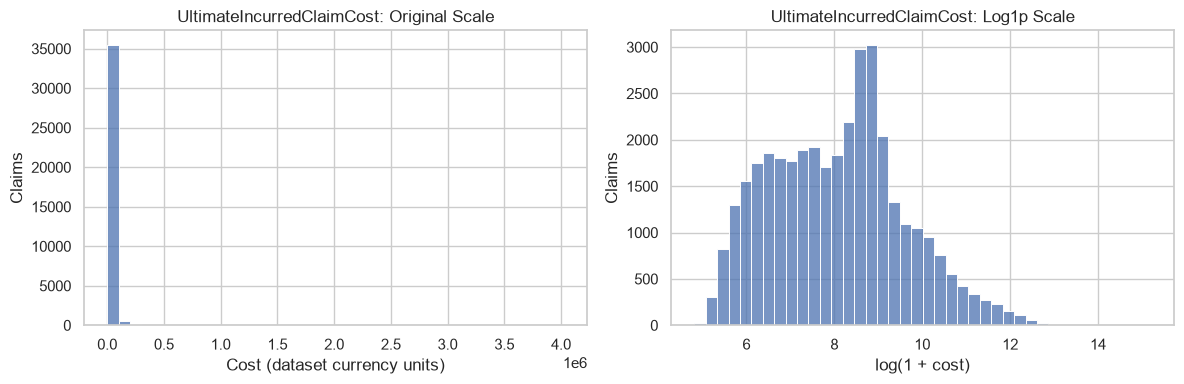

In [12]:
money_cols = [
    col for col in [INITIAL_COST_COL, ULTIMATE_COST_COL]
    if col in eda_df.columns
]

for col in money_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        data=eda_df,
        x=col,
        bins=40,
        ax=axes[0]
    )
    axes[0].set_title(f"{col}: Original Scale")
    axes[0].set_xlabel("Cost (dataset currency units)")
    axes[0].set_ylabel("Claims")

    positive_values = eda_df.loc[
        eda_df[col] > 0, col
    ]

    sns.histplot(
        x=np.log1p(positive_values),
        bins=40,
        ax=axes[1]
    )
    axes[1].set_title(f"{col}: Log1p Scale")
    axes[1].set_xlabel("log(1 + cost)")
    axes[1].set_ylabel("Claims")

    plt.tight_layout()
    plt.show()

In [13]:
required_cols = [
    "InitialIncurredCalimsCost",
    "UltimateIncurredClaimCost"
]

if all(col in eda_df.columns for col in required_cols):
    valid_costs = (
        eda_df["InitialIncurredCalimsCost"].notna()
        & eda_df["UltimateIncurredClaimCost"].notna()
    )

    eda_df["ReserveShortfall"] = (
        eda_df["UltimateIncurredClaimCost"]
        - eda_df["InitialIncurredCalimsCost"]
    )

    # Only define a log development ratio where
    # both amounts are strictly positive.
    valid_ratio = (
        valid_costs
        & (eda_df["InitialIncurredCalimsCost"] > 0)
        & (eda_df["UltimateIncurredClaimCost"] > 0)
    )

    eda_df["LogDevelopmentRatio"] = np.nan

    eda_df.loc[valid_ratio, "LogDevelopmentRatio"] = np.log(
        eda_df.loc[
            valid_ratio, "UltimateIncurredClaimCost"
        ]
        / eda_df.loc[
            valid_ratio, "InitialIncurredCalimsCost"
        ]
    )

    print("Valid reserve comparisons:", valid_costs.sum())
    print("Valid log ratios:", valid_ratio.sum())

    display(
        eda_df[
            required_cols + [
                "ReserveShortfall",
                "LogDevelopmentRatio"
            ]
        ].describe().T
    )
else:
    print("Required monetary columns are not both available.")


Valid reserve comparisons: 36176
Valid log ratios: 36176


,count,mean,std,min,25%,50%,75%,max
InitialIncurredCalimsCost,"36,176.00","7,743.59","18,223.70",1.00,700.00,"2,000.00","9,500.00","830,000.00"
UltimateIncurredClaimCost,"36,176.00","10,952.82","35,296.14",121.89,925.74,"3,373.86","8,186.85","4,027,135.94"
ReserveShortfall,"36,176.00","3,209.23","32,567.69","-663,152.27",-525.23,82.70,"1,423.86","3,984,135.94"
LogDevelopmentRatio,"36,176.00",0.24,0.81,-2.90,-0.29,0.06,0.59,9.06


In [14]:
print(df.shape)
print(df.columns.tolist())

(36176, 15)
['ClaimNumber', 'DateTimeOfAccident', 'DateReported', 'Age', 'Gender', 'MaritalStatus', 'DependentChildren', 'DependentsOther', 'WeeklyWages', 'PartTimeFullTime', 'HoursWorkedPerWeek', 'DaysWorkedPerWeek', 'ClaimDescription', 'InitialIncurredCalimsCost', 'UltimateIncurredClaimCost']


   InitialIncurredCalimsCost  UltimateIncurredClaimCost
0                       1500                   4,748.20
1                       5500                   6,326.29
2                       1700                   2,293.95
3                      15000                  17,786.49
4                       2800                   4,014.00
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36176 entries, 0 to 36175
Data columns (total 2 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   InitialIncurredCalimsCost  36176 non-null  int64  
 1   UltimateIncurredClaimCost  36176 non-null  float64
dtypes: float64(1), int64(1)
memory usage: 565.4 KB
None
InitialIncurredCalimsCost    0
UltimateIncurredClaimCost    0
dtype: int64
       InitialIncurredCalimsCost  UltimateIncurredClaimCost
count                  36,176.00                  36,176.00
mean                    7,743.59                  10,952.82
std                 

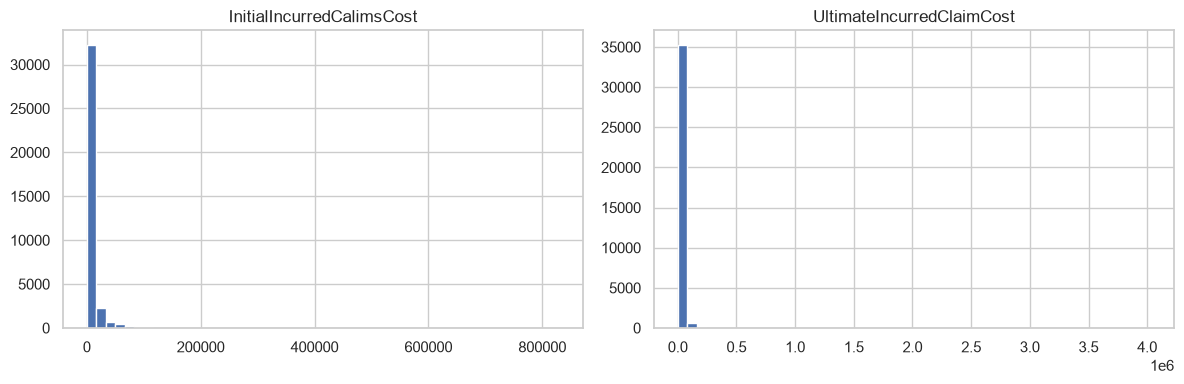

In [15]:
# Correct column names from your dataset
initial_col = "InitialIncurredCalimsCost"
ultimate_col = "UltimateIncurredClaimCost"

# Check that both columns exist
print(eda_df[[initial_col, ultimate_col]].head())

# Check data types and missing values
print(eda_df[[initial_col, ultimate_col]].info())
print(eda_df[[initial_col, ultimate_col]].isna().sum())

# Create a clean subset for comparing the two costs
plot_df = eda_df[[initial_col, ultimate_col]].dropna().copy()

# Basic summary statistics
print(plot_df.describe())

# Visualise both cost distributions
plot_df.hist(bins=50, figsize=(12, 4))
plt.tight_layout()
plt.show()

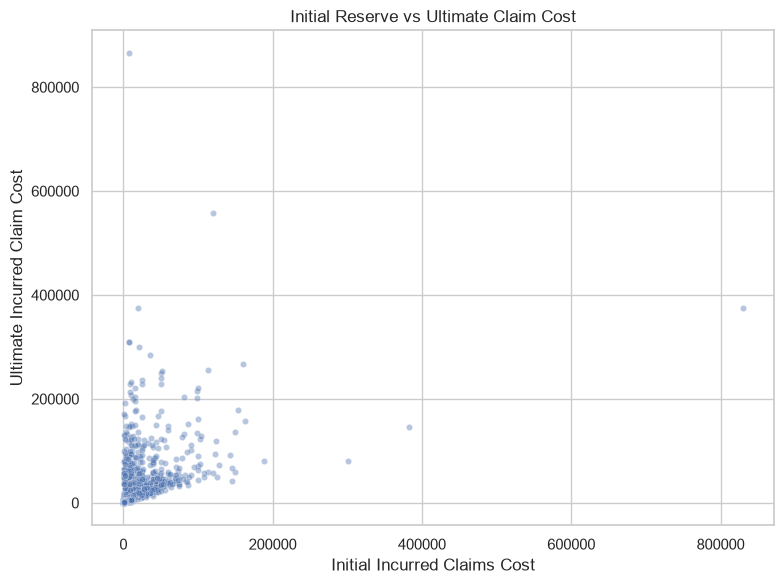

In [16]:
plot_df = eda_df.dropna(
    subset=[
        "InitialIncurredCalimsCost",
        "UltimateIncurredClaimCost"
    ]
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=plot_df.sample(
        min(5000, len(plot_df)),
        random_state=RANDOM_STATE
    ),
    x="InitialIncurredCalimsCost",
    y="UltimateIncurredClaimCost",
    alpha=0.4,
    s=20
)

plt.title("Initial Reserve vs Ultimate Claim Cost")
plt.xlabel("Initial Incurred Claims Cost")
plt.ylabel("Ultimate Incurred Claim Cost")
plt.tight_layout()
plt.show()

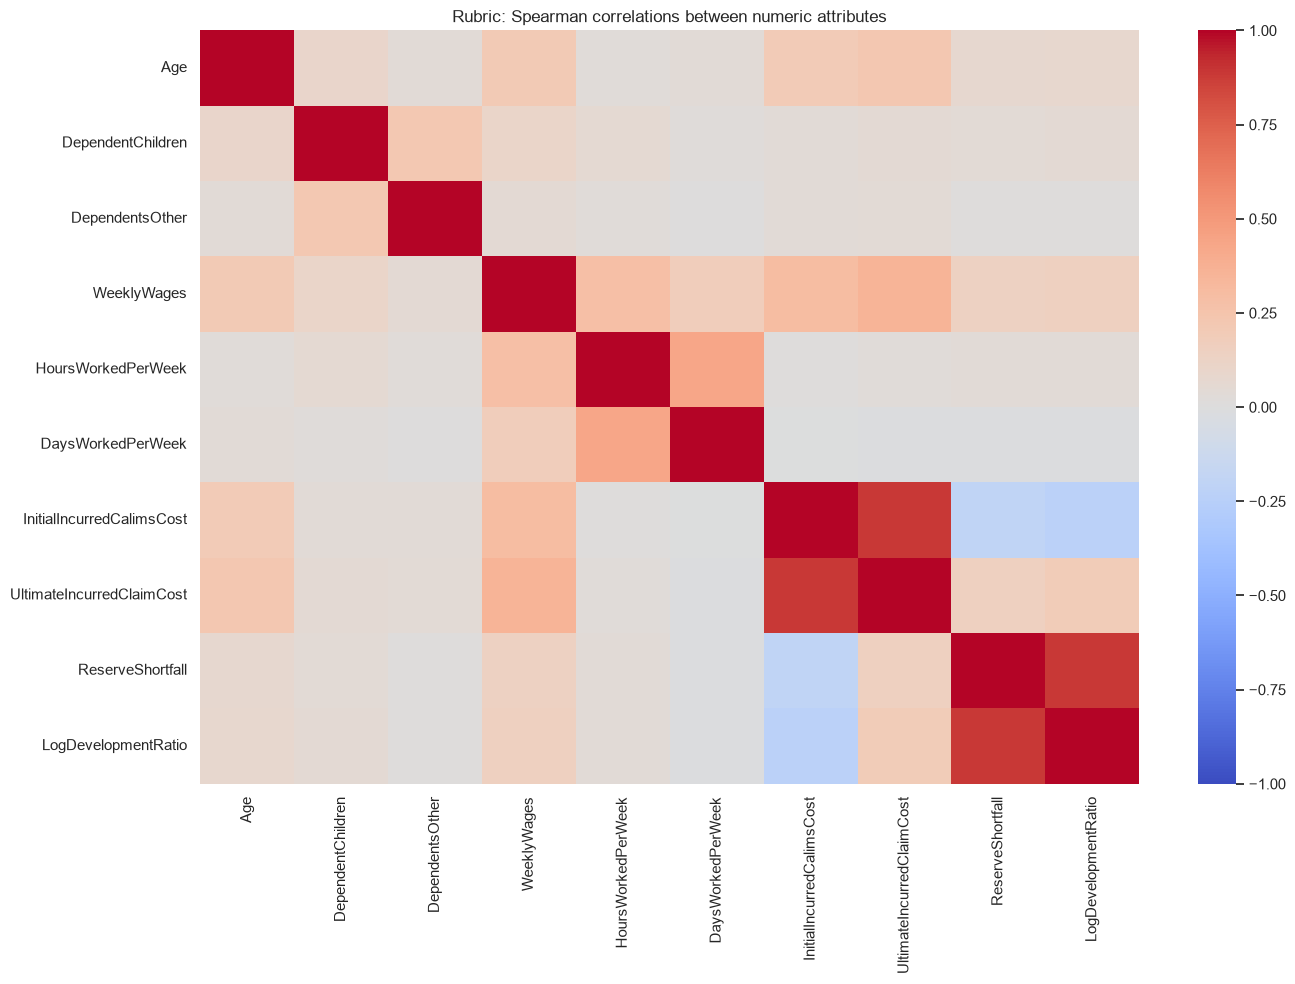

In [17]:
numeric_df = eda_df.select_dtypes(
    include=np.number
)

corr = numeric_df.corr(method="spearman")

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Rubric: Spearman correlations between numeric attributes")
plt.tight_layout()
plt.show()

Unparseable dates:


,count
DateTimeOfAccident,0
DateReported,0


Negative reporting lags: 2
Reporting lags over 1 year: 225


count   36,176.00
mean        38.63
std         60.50
min         -0.67
25%         13.42
50%         21.67
75%         40.46
95%        120.69
99%        288.58
max      1,088.50
Name: ReportingLagDays, dtype: float64

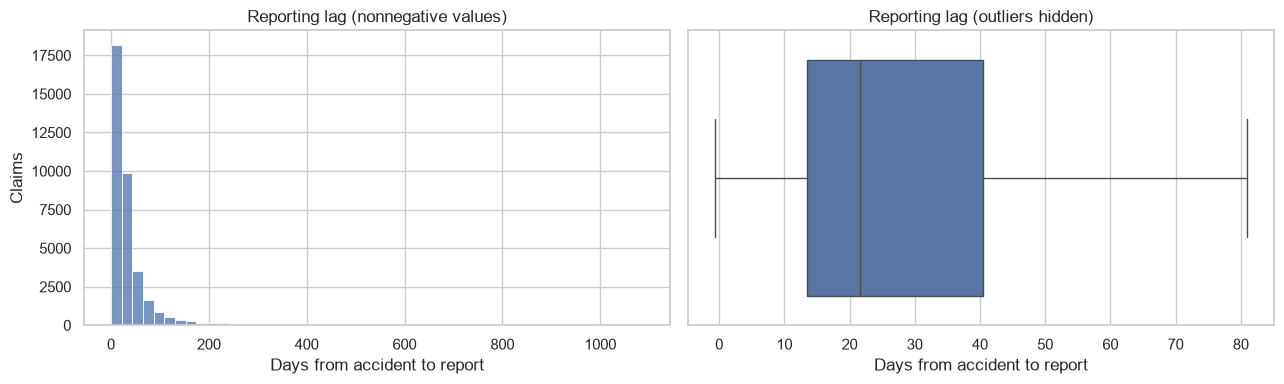

In [18]:
date_cols = ["DateTimeOfAccident", "DateReported"]
for col in date_cols:
    eda_df[col] = pd.to_datetime(eda_df[col], errors="coerce", utc=True)

date_parse_failures = eda_df[date_cols].isna().sum()
eda_df["ReportingLagDays"] = (
    eda_df["DateReported"] - eda_df["DateTimeOfAccident"]
).dt.total_seconds() / 86400
eda_df["AccidentYear"] = eda_df["DateTimeOfAccident"].dt.year
eda_df["AccidentDayOfWeek"] = eda_df["DateTimeOfAccident"].dt.day_name()
eda_df["AccidentHour"] = eda_df["DateTimeOfAccident"].dt.hour

print("Unparseable dates:")
display(date_parse_failures.to_frame("count"))
print(f"Negative reporting lags: {eda_df['ReportingLagDays'].lt(0).sum():,}")
print(f"Reporting lags over 1 year: {eda_df['ReportingLagDays'].gt(365).sum():,}")
display(eda_df["ReportingLagDays"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(eda_df["ReportingLagDays"].dropna().clip(lower=0), bins=50, ax=axes[0])
axes[0].set(title="Reporting lag (nonnegative values)", xlabel="Days from accident to report", ylabel="Claims")
sns.boxplot(data=eda_df, x="ReportingLagDays", ax=axes[1], showfliers=False)
axes[1].set(title="Reporting lag (outliers hidden)", xlabel="Days from accident to report")
plt.tight_layout()
plt.show()

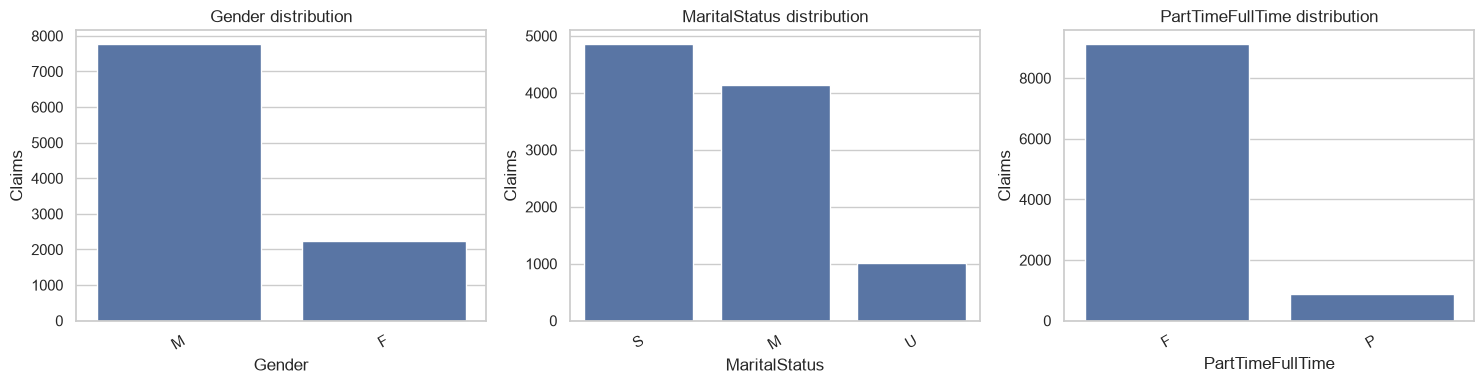

Claim-description word-count summary:


,words
count,"36,176.00"
mean,7.02
std,1.66
min,1.00
50%,7.00
90%,9.00
99%,11.00
max,14.00


Most frequent claim descriptions:


,claim_count
ClaimDescription,
SLIPPED ON ROLLER TENDONITIS RIGHT SHOULDER,218
SORTING ALUMINIUM BARS STRAIN SHOULDER NECK,187
SLIPPED USING LATHE IN EYE CORNEA,186
REDBACK SPIDER BITE RIGHT FOOT RIGHT FRACTURE,185
LIFTING BACK STRAIN LOWER BACK STRAIN,180
LIFTING TYRES LOWER BACK STRAIN,165
HIT AIR HOSE LACERATED LIP,160
FELL DOWN STAIRS BACK SPRAIN,156
JAMMED RIGHT HAND PUNCTURE WOUND RIGHT ARM,155


Data-quality screening counts (review; do not automatically delete):


,rows
Exact duplicate rows,0
Rows with a repeated ClaimNumber,12560
Age outside 14-100 (screening range),4
Hours outside 0-168 per week,75
Days outside 0-7 per week,0
Negative weekly wages,0
Nonpositive initial reserves,0
Nonpositive ultimate costs,0
Negative reporting lag,2


,count,mean,std,min,25%,50%,75%,max
WeeklyWages,"36,120.00",416.47,243.88,1.00,200.00,393.37,500.00,"7,497.00"
HoursWorkedPerWeek,"36,127.00",37.77,12.49,0.00,38.00,38.00,40.00,640.00
ApproxHourlyWage,"36,055.00",11.31,7.80,0.01,5.71,10.57,13.61,519.20


In [19]:
categorical_cols = ["Gender", "MaritalStatus", "PartTimeFullTime"]
fig, axes = plt.subplots(1, len(categorical_cols), figsize=(15, 4))
for ax, col in zip(axes, categorical_cols):
    order = eda_sample[col].value_counts().index
    sns.countplot(data=eda_sample, x=col, order=order, ax=ax)
    ax.set(title=f"{col} distribution", xlabel=col, ylabel="Claims")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

text_words = eda_df["ClaimDescription"].fillna("").str.split().str.len()
print("Claim-description word-count summary:")
display(text_words.describe(percentiles=[0.5, 0.9, 0.99]).to_frame("words"))
print("Most frequent claim descriptions:")
display(eda_df["ClaimDescription"].value_counts().head(10).to_frame("claim_count"))

quality_checks = pd.Series({
    "Exact duplicate rows": eda_df.duplicated().sum(),
    "Rows with a repeated ClaimNumber": eda_df["ClaimNumber"].duplicated(keep=False).sum(),
    "Age outside 14-100 (screening range)": (~eda_df["Age"].between(14, 100)).sum(),
    "Hours outside 0-168 per week": (~eda_df["HoursWorkedPerWeek"].between(0, 168)).sum(),
    "Days outside 0-7 per week": (~eda_df["DaysWorkedPerWeek"].between(0, 7)).sum(),
    "Negative weekly wages": eda_df["WeeklyWages"].lt(0).sum(),
    "Nonpositive initial reserves": eda_df[INITIAL_COST_COL].le(0).sum(),
    "Nonpositive ultimate costs": eda_df[ULTIMATE_COST_COL].le(0).sum(),
    "Negative reporting lag": eda_df["ReportingLagDays"].lt(0).sum(),
})
print("Data-quality screening counts (review; do not automatically delete):")
display(quality_checks.to_frame("rows"))

valid_hours = eda_df["HoursWorkedPerWeek"].gt(0)
eda_df["ApproxHourlyWage"] = np.nan
eda_df.loc[valid_hours, "ApproxHourlyWage"] = (
    eda_df.loc[valid_hours, "WeeklyWages"]
    / eda_df.loc[valid_hours, "HoursWorkedPerWeek"]
)
display(eda_df[["WeeklyWages", "HoursWorkedPerWeek", "ApproxHourlyWage"]].describe().T)

## 1.5 Rubric: Document findings, promising transformations, and useful extra data

### Document what you learned
- The local `train.csv` contains **36,176 rows and 15 original attributes**, not the 54,000 rows stated in the proposal. Confirm which dataset split/version the group will use before finalizing the report.
- The attribute audit found 56 missing `WeeklyWages` values (0.15%), 49 missing `HoursWorkedPerWeek` values (0.14%), and 22 missing `MaritalStatus` values (0.06%); the other original attributes are complete. Missingness is sparse, but the affected features still need train-only imputation.
- Initial reserves have median **2,000** and mean **7,743.59** (maximum **830,000**); ultimate costs have median **3,373.86** and mean **10,952.82** (maximum **4,027,135.94**). These mean-median gaps and the original-scale plots show strong right tails. The log1p plots make the bulk more legible; high-cost claims should be investigated, not automatically removed.
- For the primary dollar-audit target, all **36,176** rows have positive initial and ultimate costs, so both `ReserveShortfall` and `LogDevelopmentRatio` are defined for every row. The dollar shortfall has median **82.70**, mean **3,209.23**, and ranges from **-663,152.27** to **3,984,135.94**: the median is close to zero, but the distribution is extremely wide and right-skewed. This supports reporting dollar errors and reviewing under-reserving separately.
- Both dates parse successfully. Reporting lag has median **21.67 days**, a 99th percentile of **288.58 days**, and maximum **1,088.50 days**; **2** rows have a negative lag and **225** exceed one year. Review these date/recording anomalies rather than silently dropping them.
- Screening flags **75** rows with hours outside 0-168 per week and **4** ages outside the broad 14-100 review range. There are no nonpositive costs, negative wages, invalid days-per-week values, or exact duplicate rows. These screening limits are review rules, not proof that a record is erroneous.
- **12,560 rows** have a `ClaimNumber` that appears more than once. Determine whether these are linked observations before splitting; if they represent repeated records for a claim, use claim-grouped validation to avoid leakage.
- Claim descriptions average **7 words** (99th percentile **11**) and have **20,596** distinct values. This supports text normalization/vectorization rather than one-hot encoding each entire phrase as a category.

### Visualize the data and interpret each chart
- **Missing values by attribute:** missingness is rare and concentrated in wages, hours, and marital status; this agrees with the profile table.
- **Missingness pattern:** the sample-level matrix makes the sparse missing cells visible; it does not suggest widespread missing records.
- **Numeric attribute histograms:** review the discrete worker/count features separately from the heavily skewed financial variables; most claims cluster at common work-hour/day values.
- **Initial reserve and ultimate cost histograms (original vs. log1p):** both costs have long right tails, and log1p makes the bulk of claims easier to compare without deleting large claims.
- **Dollar shortfall and log development ratio:** the dollar shortfall median is 82.70, but its range is -663,152.27 to 3,984,135.94; the log ratio presents proportional development on a more comparable scale.
- **Initial reserve vs. ultimate cost scatter (log-log):** costs generally rise together, while the spread around the relationship shows that initial reserve alone does not determine final cost.
- **Spearman correlation heatmap:** use rank association to inspect monotonic relationships among numeric columns; this includes target/derived columns for EDA only and is not a model feature matrix.
- **Reporting-lag histogram and boxplot:** the distribution is long-tailed, with a few negative or very long delays requiring record-level review.
- **Categorical count plots and claim-description summaries:** these show category prevalence and repeated text patterns; they motivate careful encoding and text features.

All chart axes and titles identify the quantities being compared. The data-quality screening reports counts for implausible values but intentionally does not delete or cap them.

### Identify promising transformations
- Parse timestamps with UTC, then derive accident year, weekday, hour, and reporting delay; audit negative and very long delays. Use accident year to assess time drift and inflation.
- Consider `log1p` or a suitable Tweedie/Gamma formulation for positive, heavy-tailed costs and wages. For the log development target, use `log(ultimate / initial)` only where both costs are positive; retain a separate strategy if zero/negative costs exist.
- Impute the small missing values inside a train-only preprocessing pipeline. Consider robust scaling or quantile transforms for skewed numeric features; treat extreme observations as investigation candidates, not automatic errors.
- Derive an hourly-wage proxy only when hours are positive; validate it against employment categories. Encode counts and categories appropriately, and explore TF-IDF (optionally followed by SVD) for `ClaimDescription`.
- Use `InitialIncurredCalimsCost` as the actual CSV field name (it contains a spelling typo). It is available at FNOL and can be a predictor for the dollar shortfall, but never include the ultimate cost or any target-derived column among predictors. Exclude `ClaimNumber` from features and use grouped/time-aware validation if claims share IDs.

### Identify extra data that would be useful
Useful additions include historical medical-care CPI or another medical-cost index (to express costs in constant dollars), jurisdiction/state and benefit rules, standardized injury/body-part/diagnosis codes, treatment and disability-duration information, and claim development snapshots at consistent lags. These sources need compatible dates, units, and a defensible join key. Injury/treatment data must be checked for whether it was actually available at FNOL; later information would leak into a first-notice model.

### Limitations
This file supports retrospective pattern analysis, not a causal claim that a model or case-manager intervention reduces payout. The competition data may not represent a live insurer's population or workflow. Validate the target definition, data provenance, availability timing, fairness, and dollar impact on a genuinely held-out and preferably time-based sample before making operational claims.